In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from personality.config import DATA_PATH, ITEM_COLS, TARGET, CLASS_ORDER
from personality.plot_style import apply_style, CLASS_COLORS, save_fig

apply_style()
df = pd.read_csv(DATA_PATH) #project dataset
df.shape

(19719, 23)

In [7]:
#Hilfsfunktionen
def as_percent(p):
    """Formatiert einen Anteil (0 bis 1) als Prozent-Text, z. B. 0.4286 -> '42.9 %'."""
    return f"{p * 100:.1f} %"


In [8]:

print("Shape:", df.shape)
class_share = df[TARGET].value_counts(normalize=True)
print(class_share.map(as_percent))
df.head()

Shape: (19719, 23)
target
Moderate           42.9 %
Resilient          31.3 %
Overcontroller     14.3 %
Undercontroller    11.5 %
Name: proportion, dtype: str


,N6,N8,N7,N1,N9,N10,N3,N5,E3,N2,...,E4,age,C4,E1,A4,E10,E9,gender,hand,target
0,1,1,1,1,1,1,2,1,5,5,...,2,53,1,4,5,1,5,Male,Right,Resilient
1,4,2,3,2,2,4,4,3,3,3,...,3,46,2,2,4,5,1,Female,Right,Moderate
2,5,5,5,5,5,5,5,5,1,1,...,4,14,1,5,5,1,5,Female,Right,Moderate
3,5,5,5,5,4,5,4,4,2,4,...,4,19,5,2,4,5,4,Female,Right,Overcontroller
4,3,3,3,3,3,4,3,3,3,3,...,3,25,3,3,5,5,3,Female,Right,Moderate


In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19719 entries, 0 to 19718
Data columns (total 23 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   N6      19719 non-null  int64
 1   N8      19719 non-null  int64
 2   N7      19719 non-null  int64
 3   N1      19719 non-null  int64
 4   N9      19719 non-null  int64
 5   N10     19719 non-null  int64
 6   N3      19719 non-null  int64
 7   N5      19719 non-null  int64
 8   E3      19719 non-null  int64
 9   N2      19719 non-null  int64
 10  E5      19719 non-null  int64
 11  N4      19719 non-null  int64
 12  E7      19719 non-null  int64
 13  E4      19719 non-null  int64
 14  age     19719 non-null  int64
 15  C4      19719 non-null  int64
 16  E1      19719 non-null  int64
 17  A4      19719 non-null  int64
 18  E10     19719 non-null  int64
 19  E9      19719 non-null  int64
 20  gender  19695 non-null  str  
 21  hand    19619 non-null  str  
 22  target  19719 non-null  str  
dtypes: int64(20), str(3)
m

gender (24) and hand (100) have missing values, so the pipeline needs an imputer for them. gender, hand and target are text columns, everything else is numeric. gender and hand need encoding.

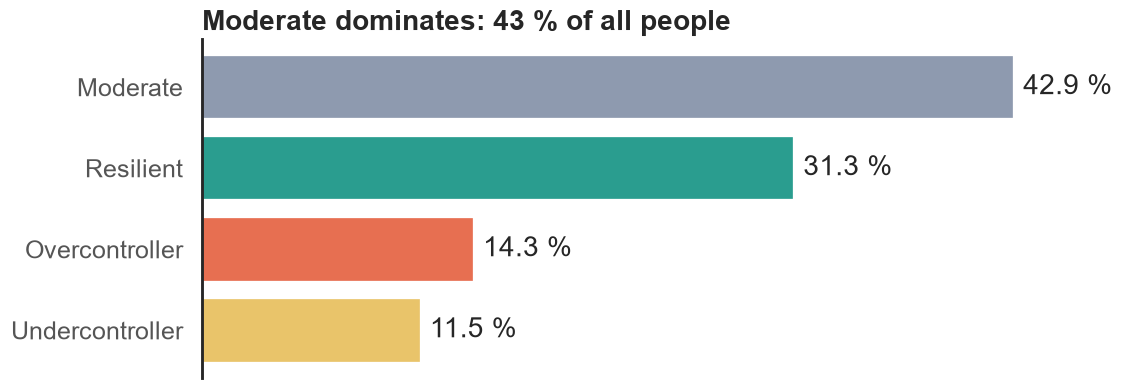

In [13]:
# Class distribution
shares = class_share.reindex(CLASS_ORDER)
colors = [CLASS_COLORS[c] for c in CLASS_ORDER]

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.barh(shares.index, shares, color=colors)
ax.bar_label(bars, labels=shares.map(as_percent), padding=6)

ax.invert_yaxis()
ax.set_xticks([])
ax.spines["bottom"].set_visible(False)
ax.set_title("Moderate dominates: 43 % of all people")

save_fig(fig, "01_class_distribution")

Classes are imbalanced. A model that always predicts “Moderate” would already reach 43 % accuracy, so accuracy is misleading and macro F1 is used as the main metric.